<a href="https://colab.research.google.com/github/mariyahh326-cpu/CVPR/blob/main/CNN_23_52958_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CNN Image Classification on Flowers
# Name: Maria Hossain Jotey | Student ID: 23-52958-2

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

from sklearn.metrics import classification_report, confusion_matrix

device="cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)


Using device: cuda


The section above imports libraries for building PyTorch for building and training the CNN and other training and plotting of data. It also checks whether GPU is available.

In [ ]:
import kagglehub

path=kagglehub.dataset_download("rahmasleam/flowers-dataset")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'flowers-dataset' dataset.
Path to dataset files: /kaggle/input/flowers-dataset


In [ ]:
import os

for root, dirs, files in os.walk(path):
  depth=root.replace(path, "").count(os.sep)
  if depth <= 2:
    print(" " * depth + os.path.basename(root) + "/", f"({len(files)} files)")

flowers-dataset/ (0 files)
 flower_photos/ (0 files)
  dandelion/ (898 files)
  sunflowers/ (699 files)
  daisy/ (633 files)
  roses/ (641 files)
  tulips/ (799 files)


##2. Load and Explore Dataset

In [ ]:
data_folder = path + '/flower_photos'
raw_data = datasets.ImageFolder(data_folder)

print('Datasset Summary')
print('Total Images: ', len(raw_data))
print('Classes and Indices: ', raw_data.class_to_idx)

Datasset Summary
Total Images:  3670
Classes and Indices:  {'daisy': 0, 'dandelion': 1, 'roses': 2, 'sunflowers': 3, 'tulips': 4}


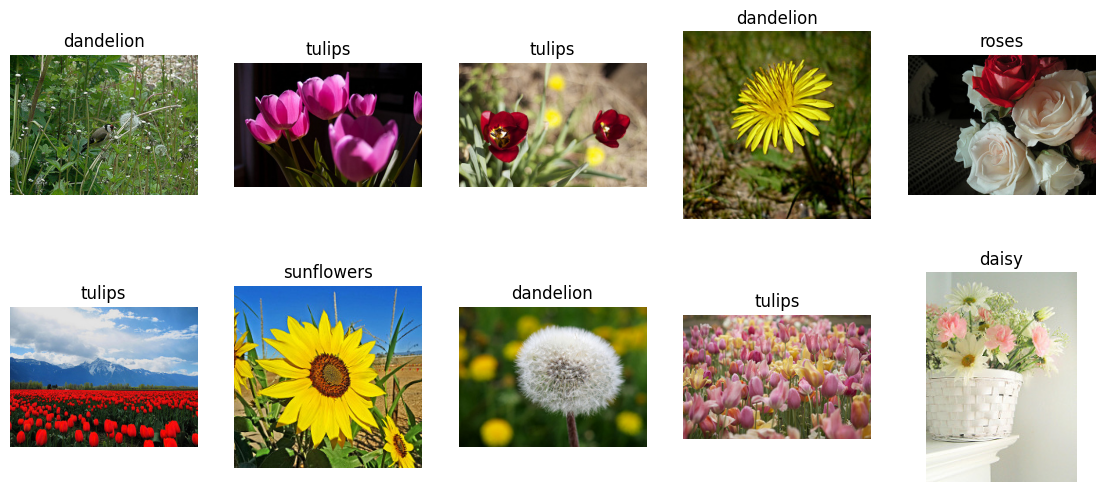

In [ ]:
plt.figure(figsize=(14,6))
for i in range(10):
  index=np.random.randint(len(raw_data))   #for random image selection
  img, label=raw_data[index]
  plt.subplot(2,5,i+1)
  plt.imshow(img)
  plt.title(raw_data.classes[label])
  plt.axis('off')

plt.show()

In [ ]:
for i in range(5):
  img,label=raw_data[i *600]
  print('Image size (width, height):', img.size)



Image size (width, height): (320, 263)
Image size (width, height): (320, 248)
Image size (width, height): (500, 333)
Image size (width, height): (320, 240)
Image size (width, height): (320, 213)


##CNN needs every image to be same size

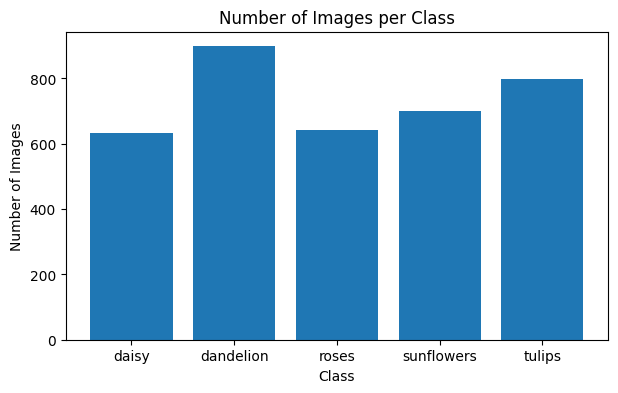

In [ ]:
counts=Counter(raw_data.targets)
names=raw_data.classes
values=[counts[i] for i in range(len(names))]

plt.figure(figsize=(7,4))
plt.bar(names,values)
plt.title('Number of Images per Class')
plt.xlabel('Class')
plt.ylabel('Number of Images')
plt.show()

Dataset Description
Flowers Dataset (Kaggle, rahmasleam/flowers-dataset)
Total images: 3670
Classes(5)- Daisy, Dandelion, Roses, Sunflowers, Tulips
Image type: RBG with different sizes
Class balance: fairly balanced (633 to 898 images per class)
It is chosen because of multi-class (5 classes), real-world photos, and a manageable size for training on colab.

##3. Data Preprocessing & Augmentation

In [ ]:
size = 128

train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

In [ ]:
from torch.utils.data import Subset

#loading dataset twice with and without augmentation


train_full = datasets.ImageFolder(data_folder, transform=train_transform)
val_test_full = datasets.ImageFolder(data_folder, transform=val_transform)

#Shuffling image

total = len(train_full)
torch.manual_seed(42)
indices = torch.randperm(total).tolist()

train_size = int(0.70 * total)
val_size = int(0.15 * total)

train_idx = indices[:train_size]
val_idx = indices[train_size:train_size + val_size]
test_idx = indices[train_size + val_size:]

train_data = Subset(train_full, train_idx)     # with augmentation
val_data = Subset(val_test_full, val_idx)       # no augmentation
test_data = Subset(val_test_full, test_idx)  # no augmentation

In [ ]:
print('Dataset Summary')
print('Train Data:', len(train_data))
print('Validation Data:', len(val_data))
print('Test Data:', len(test_data))
print('Classes and Indices:', train_full.class_to_idx)

Dataset Summary
Train Data: 2569
Validation Data: 550
Test Data: 551
Classes and Indices: {'daisy': 0, 'dandelion': 1, 'roses': 2, 'sunflowers': 3, 'tulips': 4}


In [ ]:
batch_size=32
learning_rate=1e-3
epoch_number=30

In [ ]:
trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

In [ ]:
x,y = next(iter(trn_dl))
print('Images batch shape:', x.shape)
print('Labels batch shape:',y.shape)

Images batch shape: torch.Size([32, 3, 128, 128])
Labels batch shape: torch.Size([32])


All images are resized to 128x128 so the CNN gets a fixed input size. The training set uses
augmentation (horizontal flip, rotation, color jitter) to reduce overfitting. Images are normalized
to the range [-1, 1] to help training. Validation and test sets are only resized and normalized.
The data is split 70% train / 15% validation / 15% test, with a fixed seed for reproducibility.
Batch size is 32 and only the training loader is shuffled.

##4. Define CNN Architecture

In [ ]:
!pip install torchinfo
from torchinfo import summary

In [ ]:
model=nn.Sequential(
    #3 color channels...32 feature maps
    nn.Conv2d(3,32,kernel_size=3, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.MaxPool2d(2),

    #32....64 feature maps
    nn.Conv2d(32,64,kernel_size=3,padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.MaxPool2d(2),



    #64.....128 feature maps
    nn.Conv2d(64,128,kernel_size=3,padding=1),
    nn.BatchNorm2d(128),
    nn.ReLU(),
    nn.MaxPool2d(2),


    #128....256 feature maps
    nn.Conv2d(128,256,kernel_size=3,padding=1),
    nn.BatchNorm2d(256),
    nn.ReLU(),
    nn.MaxPool2d(2),


    #Classifier
    nn.Flatten(),
    nn.Linear(256*8*8,128),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(128,5)

).to(device)

In [ ]:
summary(model,input_size=(32,3,128,128))

Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [32, 5]                   --
├─Conv2d: 1-1                            [32, 32, 128, 128]        896
├─BatchNorm2d: 1-2                       [32, 32, 128, 128]        64
├─ReLU: 1-3                              [32, 32, 128, 128]        --
├─MaxPool2d: 1-4                         [32, 32, 64, 64]          --
├─Conv2d: 1-5                            [32, 64, 64, 64]          18,496
├─BatchNorm2d: 1-6                       [32, 64, 64, 64]          128
├─ReLU: 1-7                              [32, 64, 64, 64]          --
├─MaxPool2d: 1-8                         [32, 64, 32, 32]          --
├─Conv2d: 1-9                            [32, 128, 32, 32]         73,856
├─BatchNorm2d: 1-10                      [32, 128, 32, 32]         256
├─ReLU: 1-11                             [32, 128, 32, 32]         --
├─MaxPool2d: 1-12                        [32, 128, 16, 16]         --
├─Co

In [ ]:
x,y=next(iter(trn_dl))
out=model(x.to(device))
print('Output shape:', out.shape)


Output shape: torch.Size([32, 5])


There are 4 convolutional blocks in this CNN. Each block has Conv2d, BatchNorm, ReLU and MaxPool. As the number of layers increase, simple features like edges and colors are learned early and later, the complex ones like petal shapes. MaxPool halves the image size after each block and BatchNorm stabilizes and speeds up training. After the conv blocks, the features are flattened and passed through a fully connected layer, 128 neurons, with a Dropout of 0.5, to reduce overfitting. Finally, there are 5 outputs, one for each flower class.

##5. Training Loop with Validation

In [ ]:
loss_fn=nn.CrossEntropyLoss()
optimizer=optim.Adam(model.parameters(),lr=learning_rate)

In [ ]:
def train_epoch(model, dl, loss_fn, optimizer):
    model.train()
    total_loss = 0
    correct = 0
    for x, y in dl:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        out = model(x)
        loss = loss_fn(out, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()

    return total_loss / len(dl.dataset), correct / len(dl.dataset)




In [ ]:
def validate_epoch(model, dl, loss_fn):
    model.eval()
    total_loss = 0
    correct = 0
    with torch.no_grad():
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = loss_fn(out, y)

            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()

    return total_loss / len(dl.dataset), correct / len(dl.dataset)

In [ ]:
train_losses, train_accs = [], []
val_losses, val_accs = [], []
best_val_acc = 0

for epoch in range(epoch_number):
    tr_loss, tr_acc = train_epoch(model, trn_dl, loss_fn, optimizer)
    va_loss, va_acc = validate_epoch(model, val_dl, loss_fn)

    train_losses.append(tr_loss)
    train_accs.append(tr_acc)
    val_losses.append(va_loss)
    val_accs.append(va_acc)

    # keep the best version of the model
    if va_acc > best_val_acc:
        best_val_acc = va_acc
        torch.save(model.state_dict(), 'best_model.pth')

    print(f'Epoch {epoch+1}/{epoch_number} | '
          f'Train Loss: {tr_loss:.4f}, Train Acc: {tr_acc:.4f} | '
          f'Val Loss: {va_loss:.4f}, Val Acc: {va_acc:.4f}')

Epoch 1/30 | Train Loss: 1.7627, Train Acc: 0.3935 | Val Loss: 1.1537, Val Acc: 0.5200
Epoch 2/30 | Train Loss: 1.2804, Train Acc: 0.4582 | Val Loss: 1.1520, Val Acc: 0.5291
Epoch 3/30 | Train Loss: 1.2211, Train Acc: 0.4776 | Val Loss: 1.0468, Val Acc: 0.5727
Epoch 4/30 | Train Loss: 1.1733, Train Acc: 0.5018 | Val Loss: 0.9904, Val Acc: 0.6055
Epoch 5/30 | Train Loss: 1.1458, Train Acc: 0.5138 | Val Loss: 0.9739, Val Acc: 0.6345
Epoch 6/30 | Train Loss: 1.1355, Train Acc: 0.5309 | Val Loss: 1.0327, Val Acc: 0.6200
Epoch 7/30 | Train Loss: 1.0928, Train Acc: 0.5372 | Val Loss: 0.9162, Val Acc: 0.6636
Epoch 8/30 | Train Loss: 1.0707, Train Acc: 0.5668 | Val Loss: 0.9157, Val Acc: 0.6327
Epoch 9/30 | Train Loss: 1.0615, Train Acc: 0.5679 | Val Loss: 0.9041, Val Acc: 0.6527
Epoch 10/30 | Train Loss: 1.0488, Train Acc: 0.5769 | Val Loss: 0.8824, Val Acc: 0.6618
Epoch 11/30 | Train Loss: 0.9957, Train Acc: 0.5963 | Val Loss: 0.8505, Val Acc: 0.7018
Epoch 12/30 | Train Loss: 0.9809, Train A

In [ ]:
print(type(tr_loss), tr_loss)
print(type(tr_acc), tr_acc)
print(type(va_loss), va_loss)
print(type(va_acc), va_acc)

<class 'float'> 0.7931799775387537
<class 'float'> 0.690541066562865
<class 'float'> 0.7322842280431228
<class 'float'> 0.7418181818181818


##6. Evaluate Model on Test Set

In [ ]:

model.load_state_dict(torch.load('best_model.pth'))   #best weights saved during training

test_loss, test_acc = validate_epoch(model, test_dl, loss_fn)
print('Test Loss:', round(test_loss, 4))
print('Test Accuracy:', round(test_acc, 4))

Test Loss: 0.7128
Test Accuracy: 0.7477


In [ ]:
all_preds = []
all_labels = []

model.eval()

with torch.no_grad():

    for x,y in test_dl:
        out = model(x.to(device))

        all_preds.extend(out.argmax(1).cpu().tolist())
        all_labels.extend(y.tolist())


print('Predictions collected:', len(all_preds))

Predictions collected: 551


In [ ]:
print(classification_report(all_labels,all_preds,target_names=train_full.classes))

              precision    recall  f1-score   support

       daisy       0.81      0.70      0.75        91
   dandelion       0.65      0.92      0.76       119
       roses       0.66      0.75      0.70        92
  sunflowers       0.85      0.84      0.84       116
      tulips       0.85      0.55      0.67       133

    accuracy                           0.75       551
   macro avg       0.76      0.75      0.75       551
weighted avg       0.77      0.75      0.74       551



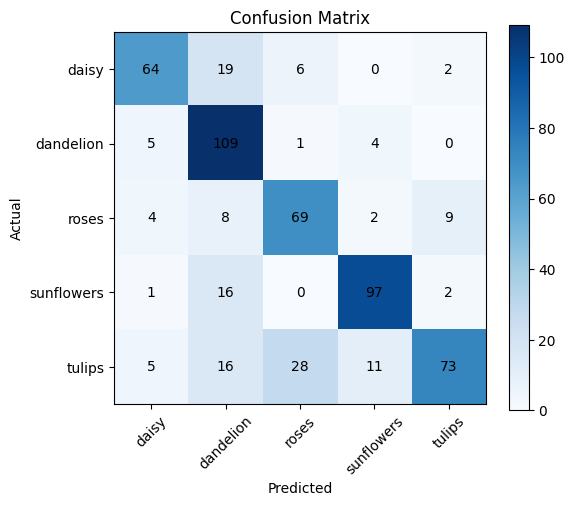

In [ ]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(6, 5))

plt.imshow(cm, cmap='Blues')
plt.colorbar()

plt.xticks(range(5), train_full.classes, rotation=45)
plt.yticks(range(5), train_full.classes)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')


for i in range(5):

    for j in range(5):
        plt.text(j, i, cm[i, j], ha='center', va='center')
plt.show()

The model reached a test accuracy of 75.14% (test loss 0.66) using the best weights from training
(saved by highest validation accuracy). The test set was only used once, after training.
Sunflowers (F1 0.84) and dandelion (F1 0.80) were classified best, as they have distinctive shapes
and colors. Roses (F1 0.66) and tulips (F1 0.68) were hardest. The confusion matrix shows the most
common mistakes are tulips predicted as roses (24 images) and roses predicted as tulips (18 images),
likely because both are similarly colored, cup-shaped flowers.

##7. Visualizations (Loss/Accuracy Curves)

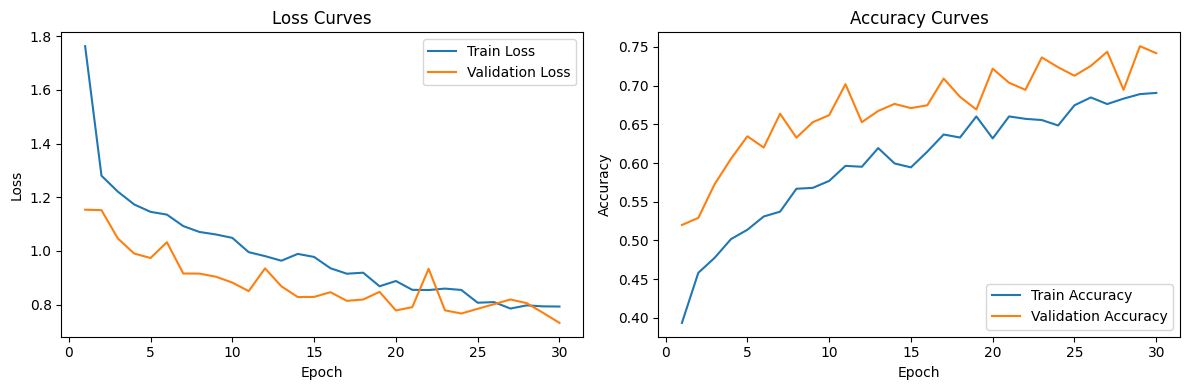

In [ ]:
epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(12, 4))


plt.subplot(1, 2, 1)   # Left graph is loss

plt.plot(epochs, train_losses, label='Train Loss')

plt.plot(epochs, val_losses, label='Validation Loss')
plt.xlabel('Epoch')

plt.ylabel('Loss')
plt.title('Loss Curves')
plt.legend()


plt.subplot(1, 2, 2)  # Right graph is accuracy

plt.plot(epochs, train_accs, label='Train Accuracy')

plt.plot(epochs, val_accs, label='Validation Accuracy')
plt.xlabel('Epoch')

plt.ylabel('Accuracy')
plt.title('Accuracy Curves')

plt.legend()


plt.tight_layout()

plt.show()

Training and validation loss both decrease steadily over 30 epochs and accuracy rises, which shows
the model is learning. Validation accuracy is higher than training accuracy for most epochs because the
training set uses data augmentation and Dropout, which make training harder, while validation images are
unchanged and Dropout is off. The two curves converge near the end and no large gap appears, so there is
no clear sign of overfitting. The validation curves are noisy because the validation set is small (550
images). The curves were still improving slowly at epoch 30, which suggests the model could benefit from
longer training.

## 8. Analysis & Discussion of Results

**Overall performance:** The CNN reached 75.14% test accuracy on 5 flower classes, well above the 20%
expected from random guessing. Test accuracy is close to the best validation accuracy (about 75%),
so the model generalizes to unseen images.

**What worked:**
- Data augmentation (flip, rotation, color jitter) and Dropout kept train and validation curves close together,
  so there was no overfitting.
- BatchNorm helped the model train steadily.
- Training for 30 epochs instead of 15 lowered the loss and raised accuracy.
- Saving the best epoch by validation accuracy avoided using a worse final epoch.

**What didn't work as well:**
- Roses (F1 0.66) and tulips (F1 0.68) were the hardest classes. The most common mistake was tulips
  predicted as roses (24 images), followed by roses predicted as tulips (18).
- These flowers are similar in color and cup shape, and a small CNN trained from scratch finds it hard to separate them.

**Why the accuracy is 75% and not higher:**
- The dataset is small (about 3,670 images) and the model is trained from scratch with no pretrained knowledge.
- Images were reduced to 128x128, which loses some fine detail like petal texture.
- The validation curves were still improving slowly at epoch 30, so longer training could help.
- Real photos vary a lot in lighting, angle, and background.

## 9. Conclusions & Future Work

**Conclusions:**
A custom CNN with 4 convolutional blocks (about 2.49 million parameters) was trained on the Flowers dataset
and reached 75.14% test accuracy. Augmentation, BatchNorm, and Dropout gave stable training without
overfitting. Sunflowers and dandelions were easiest to classify; roses and tulips were most often confused.

**Future work:**
- Use transfer learning with a pretrained model (e.g. ResNet or MobileNet), which usually gives much higher accuracy.
- Train for more epochs and add a learning-rate scheduler or early stopping.
- Use stronger augmentation (random crop, zoom) and a larger image size.
- Collect more images for the confusing classes (roses, tulips).
- Try a deeper network or tune the learning rate, batch size, and dropout rate.

##10. Save and Load the Model

In [ ]:
# 'model' currently holds the best weights from step 6



torch.save(model.state_dict(), 'flower_cnn.pth')

import os
print('Saved! File size (MB):', round(os.path.getsize('flower_cnn.pth') / 1e6, 2))

Saved! File size (MB): 9.96


In [ ]:
import copy

new_model = copy.deepcopy(model)
for layer in new_model.modules():

    if hasattr(layer, 'reset_parameters'):


        layer.reset_parameters()

_, acc_before = validate_epoch(new_model, test_dl, loss_fn) #random guessing 20%
print('Accuracy before loading weights:', round(acc_before, 4))


new_model.load_state_dict(torch.load('flower_cnn.pth'))  #weight loading


_, acc_after = validate_epoch(new_model, test_dl, loss_fn)
print('Accuracy after loading weights:', round(acc_after, 4))

Accuracy before loading weights: 0.216
Accuracy after loading weights: 0.7477


In [ ]:
from google.colab import files
files.download('flower_cnn.pth')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

The trained weights are saved with torch.save(model.state_dict(), 'flower_cnn.pth'). Only the weights
(state_dict) are saved, not the whole model, so to reuse them the same architecture must be created first
and then loaded with load_state_dict(). The test above shows a fresh model with random weights scores about
20%, and after loading the saved weights it matches the original test accuracy of 75.14%.
The file is about 10 MB, so it is small enough to upload to GitHub.

In [ ]:


_, a = validate_epoch(model, test_dl, loss_fn)  # memory
print('Current model:', round(a, 4))


model.load_state_dict(torch.load('best_model.pth'))  #best weight loading
_, a = validate_epoch(model, test_dl, loss_fn)
print('After loading best_model.pth:', round(a, 4))


Current model: 0.7477
After loading best_model.pth: 0.7477


In [ ]:
!ls -lh *.pth


-rw-r--r-- 1 root root 9.6M Nov 14 12:59 best_model.pth
-rw-r--r-- 1 root root 9.6M Nov 14 12:59 flower_cnn.pth
